In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Entorno:", sys.executable)
print("Pandas:", pd.__version__)

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Entorno: c:\Users\horac\TC5061-Proyecto-Equipo16\.venv\Scripts\python.exe
Pandas: 3.0.6


# Análisis exploratorio de viajes MiBici

**Proyecto:** TC5061 - Equipo 16  
**Responsable:** HH2  
**Periodo de estudio:** Octubre 2024 – Septiembre 2026

## Objetivo

Explorar la calidad, distribución y comportamiento temporal de
los viajes del sistema MiBici para diseñar las variables de tres
problemas de Machine Learning:

- P1: Predicción de demanda diaria por estación (regresión).
- P2: Clasificación del riesgo de desequilibrio por franjas de 3 horas.
- P3: Agrupamiento de estaciones según sus perfiles horarios.

## Metodología

1. Validación del esquema y calidad de los datos.
2. Análisis de viajes y estaciones.
3. Exploración de la demanda diaria.
4. Análisis del flujo neto y umbrales de riesgo.
5. Exploración de perfiles horarios.
6. Definición de reglas de limpieza y feature engineering.

In [2]:
#Datos sínteticos de viajes y estaciones
viajes = pd.DataFrame({
    "viaje_id": [1, 2, 3, 4, 5, 6],
    "inicio": pd.to_datetime([
        "2026-03-01 08:00",
        "2026-03-01 08:30",
        "2026-03-01 09:00",
        "2026-03-02 17:00",
        "2026-03-02 18:00",
        "2026-03-03 07:30",
    ]),
    "fin": pd.to_datetime([
        "2026-03-01 08:15",
        "2026-03-01 08:50",
        "2026-03-01 09:20",
        "2026-03-02 17:15",
        "2026-03-02 18:20",
        "2026-03-03 07:45",
    ]),
    "origen_id": [1, 1, 2, 1, 2, 1],
    "destino_id": [2, 2, 1, 2, 1, 2],
})

estaciones = pd.DataFrame({
    "estacion_id": [1, 2, 3],
    "nombre": ["GDL Centro", "ZPN Norte", "GDL Sur"],
    "municipio": ["GDL", "ZPN", "GDL"],
    "latitud": [20.67, 20.70, 20.65],
    "longitud": [-103.35, -103.40, -103.33],
    "capacidad": [20, 15, 10],
    "activa": [True, True, True],
})

display(viajes)
display(estaciones)

,viaje_id,inicio,fin,origen_id,destino_id
0,1,2026-03-01 08:00:00,2026-03-01 08:15:00,1,2
1,2,2026-03-01 08:30:00,2026-03-01 08:50:00,1,2
2,3,2026-03-01 09:00:00,2026-03-01 09:20:00,2,1
3,4,2026-03-02 17:00:00,2026-03-02 17:15:00,1,2
4,5,2026-03-02 18:00:00,2026-03-02 18:20:00,2,1
5,6,2026-03-03 07:30:00,2026-03-03 07:45:00,1,2


,estacion_id,nombre,municipio,latitud,longitud,capacidad,activa
0,1,GDL Centro,GDL,20.67,-103.35,20,True
1,2,ZPN Norte,ZPN,20.70,-103.40,15,True
2,3,GDL Sur,GDL,20.65,-103.33,10,True


In [3]:
print("Total de viajes:", len(viajes))
print("Total de estaciones:", len(estaciones))

print("\nTipos de datos:")
print(viajes.dtypes)

print("\nValores faltantes:")
print(viajes.isna().sum())

print("\nViajes duplicados:")
print(viajes["viaje_id"].duplicated().sum())

viajes["duracion_min"] = (
    viajes["fin"] - viajes["inicio"]
).dt.total_seconds() / 60

print("\nEstadísticas de duración:")
display(viajes["duracion_min"].describe())

Total de viajes: 6
Total de estaciones: 3

Tipos de datos:
viaje_id               int64
inicio        datetime64[us]
fin           datetime64[us]
origen_id              int64
destino_id             int64
dtype: object

Valores faltantes:
viaje_id      0
inicio        0
fin           0
origen_id     0
destino_id    0
dtype: int64

Viajes duplicados:
0

Estadísticas de duración:


count     6.000000
mean     17.500000
std       2.738613
min      15.000000
25%      15.000000
50%      17.500000
75%      20.000000
max      20.000000
Name: duracion_min, dtype: float64

In [4]:
# ---- P1: Demanda diaria por estación ---- #

df_demanda = viajes.copy()

# Extraer fecha de inicio del viaje
df_demanda["fecha"] = df_demanda["inicio"].dt.normalize()

# Contar salidas por estación y día
df_demanda = (
    df_demanda
    .groupby(["origen_id", "fecha"])
    .size()
    .reset_index(name="demanda")
    .rename(columns={"origen_id": "estacion_id"})
)

display(df_demanda)

,estacion_id,fecha,demanda
0,1,2026-03-01,2
1,1,2026-03-02,1
2,1,2026-03-03,1
3,2,2026-03-01,1
4,2,2026-03-02,1


In [5]:
# ---- Crear calendario completo por estación ---- #

fechas = pd.date_range(
    start=viajes["inicio"].min().normalize(),
    end=viajes["inicio"].max().normalize(),
    freq="D"
)

# Todas las combinaciones estación-fecha
indice_completo = pd.MultiIndex.from_product(
    [
        estaciones["estacion_id"],
        fechas
    ],
    names=["estacion_id", "fecha"]
)

# Completar los días sin viajes con cero
df_demanda_completa = (
    df_demanda
    .set_index(["estacion_id", "fecha"])
    .reindex(indice_completo, fill_value=0)
    .reset_index()
    .sort_values(["estacion_id", "fecha"])
    .reset_index(drop=True)
)

display(df_demanda_completa)

,estacion_id,fecha,demanda
0,1,2026-03-01,2
1,1,2026-03-02,1
2,1,2026-03-03,1
3,2,2026-03-01,1
4,2,2026-03-02,1
5,2,2026-03-03,0
6,3,2026-03-01,0
7,3,2026-03-02,0
8,3,2026-03-03,0


In [6]:
# ---- Validaciones de P1 ---- #

# Se conservan las seis salidas originales
assert df_demanda_completa["demanda"].sum() == len(viajes)

# Tres estaciones durante tres días
assert len(df_demanda_completa) == 9

# La estación 3 no tiene salidas
assert (
    df_demanda_completa
    .query("estacion_id == 3")["demanda"]
    .eq(0)
    .all()
)

# No existen combinaciones duplicadas
assert not df_demanda_completa.duplicated(
    subset=["estacion_id", "fecha"]
).any()

print("Todas las validaciones de P1 fueron exitosas.")

Todas las validaciones de P1 fueron exitosas.


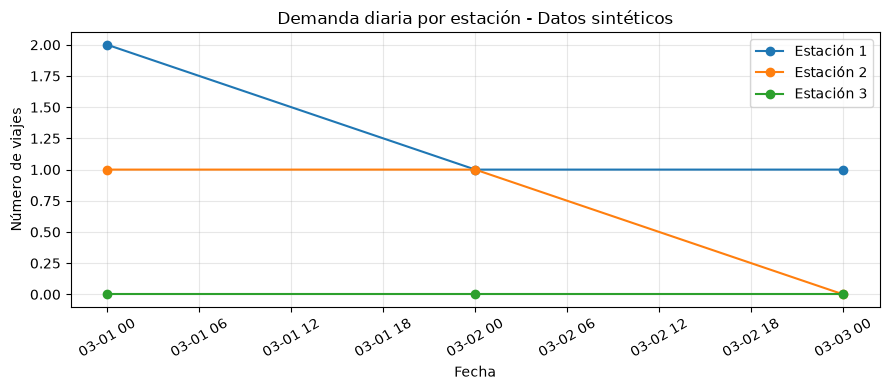

In [7]:
# ---- Visualización de demanda diaria ---- #

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

for estacion_id, grupo in df_demanda_completa.groupby("estacion_id"):
    ax.plot(
        grupo["fecha"],
        grupo["demanda"],
        marker="o",
        label=f"Estación {estacion_id}"
    )

ax.set(
    title="Demanda diaria por estación - Datos sintéticos",
    xlabel="Fecha",
    ylabel="Número de viajes"
)

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
import requests

url = "https://www.mibici.net/site/assets/files/93516/datos_abiertos_2024_11.csv"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/155.0.0.0 Safari/537.36"
    ),
    "Accept": (
        "text/html,application/xhtml+xml,application/xml;q=0.9,"
        "image/jxl,image/avif,image/webp,image/apng,*/*;q=0.8,"
        "application/signed-exchange;v=b3;q=0.7"
    ),
    "Accept-Language": "es-US,es;q=0.9,es-419;q=0.8,en;q=0.7",
    "Cache-Control": "no-cache",
    "Pragma": "no-cache",
    "Upgrade-Insecure-Requests": "1",
    "Sec-Fetch-Dest": "document",
    "Sec-Fetch-Mode": "navigate",
    "Sec-Fetch-Site": "none",
    "Sec-Fetch-User": "?1",
}

try:
    with requests.get(
        url,
        headers=headers,
        stream=True,
        timeout=(15, 30)
    ) as respuesta:
        print("Código HTTP:", respuesta.status_code)
        print("Content-Type:", respuesta.headers.get("Content-Type"))
        print("Content-Length:", respuesta.headers.get("Content-Length"))

except requests.RequestException as error:
    print("Error:", error)

Código HTTP: 200
Content-Type: text/csv
Content-Length: 33902108


In [10]:
import requests

url = "https://www.mibici.net/site/assets/files/93516/datos_abiertos_2024_11.csv"

user_agent = (
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
    "AppleWebKit/537.36 (KHTML, like Gecko) "
    "Chrome/155.0.0.0 Safari/537.36"
)

accept_chrome = (
    "text/html,application/xhtml+xml,application/xml;q=0.9,"
    "image/jxl,image/avif,image/webp,image/apng,*/*;q=0.8,"
    "application/signed-exchange;v=b3;q=0.7"
)

configuraciones = {
    "1. Solo User-Agent": {
        "User-Agent": user_agent,
    },
    "2. User-Agent + Accept": {
        "User-Agent": user_agent,
        "Accept": accept_chrome,
    },
    "3. Agregar idioma": {
        "User-Agent": user_agent,
        "Accept": accept_chrome,
        "Accept-Language": "es-US,es;q=0.9,es-419;q=0.8,en;q=0.7",
    },
}

for nombre, headers in configuraciones.items():
    try:
        with requests.get(
            url,
            headers=headers,
            stream=True,
            timeout=(15, 30)
        ) as respuesta:
            print(f"{nombre}: HTTP {respuesta.status_code}")

    except requests.RequestException as error:
        print(f"{nombre}: ERROR - {error}")

1. Solo User-Agent: HTTP 200
2. User-Agent + Accept: HTTP 200
3. Agregar idioma: HTTP 200


In [11]:
import requests

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/155.0.0.0 Safari/537.36"
    )
}

urls = {
    "Octubre 2024": "https://www.mibici.net/site/assets/files/91758/datos_abiertos_2024_10.csv",
    "Noviembre 2024": "https://www.mibici.net/site/assets/files/93516/datos_abiertos_2024_11.csv",
}

for mes, url in urls.items():
    try:
        with requests.get(
            url,
            headers=headers,
            stream=True,
            timeout=(15, 30)
        ) as respuesta:
            print(f"{mes}: HTTP {respuesta.status_code}")
    except requests.RequestException as error:
        print(f"{mes}: ERROR - {error}")

Octubre 2024: HTTP 200
Noviembre 2024: HTTP 200


In [12]:
from mibici.dataset import cargar_viajes, cargar_estaciones

viajes_reales = cargar_viajes()
estaciones_reales = cargar_estaciones()

print(f"Total de viajes: {len(viajes_reales):,}")
print(f"Total de estaciones: {len(estaciones_reales):,}")

display(viajes_reales.head())
display(estaciones_reales.head())

2026-10-16 23:57:43.289 | INFO     | mibici.config:<module>:17 - PROJ_ROOT path is: C:\Users\horac\TC5061-Proyecto-Equipo16


Total de viajes: 9,043,925
Total de estaciones: 484


,viaje_id,inicio,fin,origen_id,destino_id
0,35847248,2024-10-01 00:00:00,2024-10-01 00:21:00,40,213
1,35847249,2024-10-01 00:01:00,2024-10-01 00:18:00,189,3
2,35847250,2024-10-01 00:01:00,2024-10-01 00:11:00,131,342
3,35847251,2024-10-01 00:01:00,2024-10-01 00:18:00,189,3
4,35847252,2024-10-01 00:02:00,2024-10-01 00:12:00,244,46


,estacion_id,nombre,municipio,latitud,longitud,capacidad,activa
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,<NA>,20.666378,-103.348820,15,True
1,3,(GDL-002) C. Colonias / Av. Niños héroes,<NA>,20.667228,-103.366000,15,True
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,<NA>,20.667690,-103.368252,19,True
3,5,(GDL-004) C. Ghilardi /C. Miraflores,<NA>,20.691847,-103.362549,19,True
4,6,(GDL-005) C. San Diego /Calzada Independencia,<NA>,20.681158,-103.339363,11,True


## 2. Validación de calidad de datos reales

Se evalúa la cobertura temporal, integridad, duplicados,
valores faltantes y consistencia de los registros de viajes.

In [13]:
# ---- Cobertura temporal de viajes ---- #

print("Primer viaje:", viajes_reales["inicio"].min())
print("Último viaje:", viajes_reales["inicio"].max())

print("\nTipos de datos:")
print(viajes_reales.dtypes)

print("\nNúmero de meses registrados:")
print(viajes_reales["inicio"].dt.to_period("M").nunique())

Primer viaje: 2024-10-01 00:00:00
Último viaje: 2026-09-30 23:59:48

Tipos de datos:
viaje_id               int64
inicio        datetime64[ns]
fin           datetime64[ns]
origen_id              int32
destino_id             int32
dtype: object

Número de meses registrados:
24


In [14]:
# ---- Calidad de registros ---- #

calidad_viajes = pd.DataFrame({
    "Nulos": viajes_reales.isna().sum(),
    "Porcentaje_nulos": (
        viajes_reales.isna().mean() * 100
    ).round(2)
})

display(calidad_viajes)

print(
    "Viajes duplicados por ID:",
    viajes_reales["viaje_id"].duplicated().sum()
)

print(
    "Registros completamente duplicados:",
    viajes_reales.duplicated().sum()
)

,Nulos,Porcentaje_nulos
viaje_id,0,0.0
inicio,0,0.0
fin,0,0.0
origen_id,0,0.0
destino_id,0,0.0


Viajes duplicados por ID: 758
Registros completamente duplicados: 758


In [15]:
# ---- Duración de viajes ---- #

duracion_min = (
    viajes_reales["fin"] - viajes_reales["inicio"]
).dt.total_seconds() / 60

print("Duraciones negativas:", (duracion_min < 0).sum())
print("Duraciones iguales a cero:", (duracion_min == 0).sum())
print("Duraciones mayores a 24 horas:", (duracion_min > 1440).sum())

display(
    duracion_min.describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

Duraciones negativas: 0
Duraciones iguales a cero: 13889
Duraciones mayores a 24 horas: 21


count    9.043925e+06
mean     1.105544e+01
std      1.044033e+01
min      0.000000e+00
1%       2.000000e-01
5%       2.216667e+00
25%      5.766667e+00
50%      9.466667e+00
75%      1.483333e+01
95%      2.435000e+01
99%      3.311667e+01
max      1.150077e+04
dtype: float64

In [16]:
# ---- Calidad del catálogo de estaciones ---- #

calidad_estaciones = pd.DataFrame({
    "Nulos": estaciones_reales.isna().sum(),
    "Porcentaje_nulos": (
        estaciones_reales.isna().mean() * 100
    ).round(2)
})

display(calidad_estaciones)

print(
    "IDs de estación duplicados:",
    estaciones_reales["estacion_id"].duplicated().sum()
)

print("\nEstaciones activas:")
print(estaciones_reales["activa"].value_counts(dropna=False))

,Nulos,Porcentaje_nulos
estacion_id,0,0.00
nombre,0,0.00
municipio,483,99.79
latitud,0,0.00
longitud,0,0.00
capacidad,0,0.00
activa,0,0.00


IDs de estación duplicados: 0

Estaciones activas:
activa
True     470
False     14
Name: count, dtype: int64


In [17]:
# ---- Limpieza inicial: duplicados exactos ---- #

df_viajes_limpio = (
    viajes_reales
    .drop_duplicates()
    .copy()
)

print("Registros originales:", f"{len(viajes_reales):,}")
print("Registros posteriores:", f"{len(df_viajes_limpio):,}")
print("Duplicados eliminados:", f"{len(viajes_reales) - len(df_viajes_limpio):,}")

Registros originales: 9,043,925
Registros posteriores: 9,043,167
Duplicados eliminados: 758


In [18]:
# ---- Validación referencial de estaciones ---- #

ids_estaciones = set(estaciones_reales["estacion_id"])

origenes_no_catalogados = (
    ~df_viajes_limpio["origen_id"].isin(ids_estaciones)
)

destinos_no_catalogados = (
    ~df_viajes_limpio["destino_id"].isin(ids_estaciones)
)

print(
    "Viajes con origen fuera del catálogo:",
    f"{origenes_no_catalogados.sum():,}"
)

print(
    "Viajes con destino fuera del catálogo:",
    f"{destinos_no_catalogados.sum():,}"
)

print(
    "Viajes con alguna estación fuera del catálogo:",
    f"{(origenes_no_catalogados | destinos_no_catalogados).sum():,}"
)

print("\nEstaciones de origen no catalogadas:")
print(
    sorted(
        set(df_viajes_limpio.loc[origenes_no_catalogados, "origen_id"])
    )
)

print("\nEstaciones de destino no catalogadas:")
print(
    sorted(
        set(df_viajes_limpio.loc[destinos_no_catalogados, "destino_id"])
    )
)

Viajes con origen fuera del catálogo: 1,960
Viajes con destino fuera del catálogo: 2,123
Viajes con alguna estación fuera del catálogo: 3,954

Estaciones de origen no catalogadas:
[405, 407]

Estaciones de destino no catalogadas:
[405, 407]


In [19]:
# ---- Análisis de viajes de duración cero ---- #

df_viajes_limpio["duracion_min"] = (
    df_viajes_limpio["fin"] - df_viajes_limpio["inicio"]
).dt.total_seconds() / 60

viajes_cero = df_viajes_limpio[
    df_viajes_limpio["duracion_min"] == 0
]

print("Total de viajes de duración cero:", f"{len(viajes_cero):,}")

print(
    "Misma estación de origen y destino:",
    f"{(viajes_cero['origen_id'] == viajes_cero['destino_id']).sum():,}"
)

print(
    "Estaciones diferentes:",
    f"{(viajes_cero['origen_id'] != viajes_cero['destino_id']).sum():,}"
)

Total de viajes de duración cero: 13,889
Misma estación de origen y destino: 9,821
Estaciones diferentes: 4,068


In [20]:
# ---- Auditoría de estaciones fuera del catálogo ---- #

ids_no_catalogados = [405, 407]

resultados = []

for estacion in ids_no_catalogados:

    salidas = df_viajes_limpio[
        df_viajes_limpio["origen_id"] == estacion
    ]

    llegadas = df_viajes_limpio[
        df_viajes_limpio["destino_id"] == estacion
    ]

    resultados.append({
        "estacion_id": estacion,
        "salidas": len(salidas),
        "llegadas": len(llegadas),
        "primera_salida": salidas["inicio"].min(),
        "ultima_salida": salidas["inicio"].max(),
        "primera_llegada": llegadas["fin"].min(),
        "ultima_llegada": llegadas["fin"].max(),
    })

df_estaciones_no_catalogadas = pd.DataFrame(resultados)

display(df_estaciones_no_catalogadas)

,estacion_id,salidas,llegadas,primera_salida,ultima_salida,primera_llegada,ultima_llegada
0,405,3,3,2026-06-08 18:03:12,2026-06-08 18:06:44,2026-06-08 18:04:00,2026-06-08 19:03:17
1,407,1957,2120,2026-06-11 10:44:09,2026-07-21 21:43:40,2026-06-11 10:35:24,2026-07-21 21:38:25


,mes,total_viajes
0,2024-10,418690
1,2024-11,391089
2,2024-12,340049
3,2025-01,380184
4,2025-02,372529
5,2025-03,405110
6,2025-04,366193
7,2025-05,395891
8,2025-06,356611
9,2025-07,368186


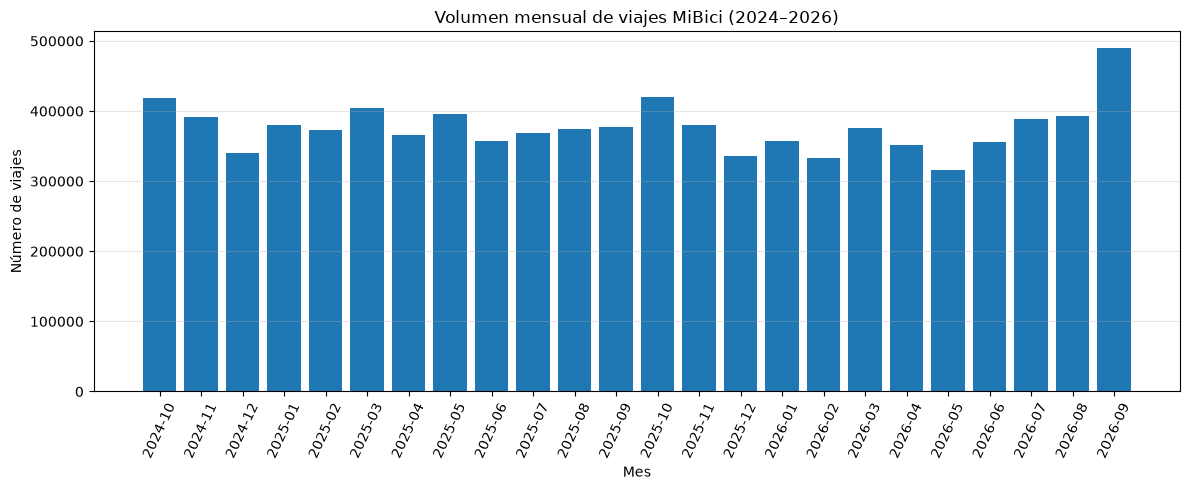

In [21]:
# ---- Volumen mensual de viajes ---- #

df_viajes_limpio["mes"] = (
    df_viajes_limpio["inicio"].dt.to_period("M")
)

viajes_mensuales = (
    df_viajes_limpio
    .groupby("mes")
    .size()
    .reset_index(name="total_viajes")
)

display(viajes_mensuales)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    viajes_mensuales["mes"].astype(str),
    viajes_mensuales["total_viajes"]
)

ax.set(
    title="Volumen mensual de viajes MiBici (2024–2026)",
    xlabel="Mes",
    ylabel="Número de viajes"
)

ax.tick_params(axis="x", rotation=65)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# ---- P1: Demanda diaria por estación ---- #

def demanda_diaria(viajes, estaciones, fecha_inicio, fecha_fin):
    """
    Calcula el número de viajes iniciados por estación y día.

    Incluye combinaciones estación-fecha sin viajes,
    asignándoles demanda igual a cero.

    Nota: supone que las estaciones seleccionadas están
    disponibles durante todo el periodo solicitado.
    """

    inicio = pd.Timestamp(fecha_inicio).normalize()
    fin = pd.Timestamp(fecha_fin).normalize()

    if inicio > fin:
        raise ValueError("fecha_inicio debe ser anterior o igual a fecha_fin")

    df = viajes.loc[
        viajes["inicio"].between(
            inicio,
            fin + pd.Timedelta(days=1),
            inclusive="left"
        ),
        ["inicio", "origen_id"]
    ].copy()

    df["fecha"] = df["inicio"].dt.normalize()

    conteos = (
        df.groupby(["origen_id", "fecha"])
        .size()
        .rename("demanda")
        .rename_axis(index=["estacion_id", "fecha"])
    )

    calendario = pd.date_range(inicio, fin, freq="D")

    indice = pd.MultiIndex.from_product(
        [
            estaciones["estacion_id"].drop_duplicates(),
            calendario
        ],
        names=["estacion_id", "fecha"]
    )

    resultado = (
        conteos
        .reindex(indice, fill_value=0)
        .reset_index()
        .sort_values(["estacion_id", "fecha"])
        .reset_index(drop=True)
    )

    return resultado

In [23]:
# ---- Prueba de demanda diaria: octubre de 2024 ---- #

df_demanda_octubre = demanda_diaria(
    viajes=df_viajes_limpio,
    estaciones=estaciones_reales,
    fecha_inicio="2024-10-01",
    fecha_fin="2024-10-31"
)

print("Registros:", f"{len(df_demanda_octubre):,}")
print("Demanda total:", f"{df_demanda_octubre['demanda'].sum():,}")

display(df_demanda_octubre.head(10))

Registros: 15,004
Demanda total: 418,690


,estacion_id,fecha,demanda
0,2,2024-10-01,21
1,2,2024-10-02,74
2,2,2024-10-03,83
3,2,2024-10-04,63
4,2,2024-10-05,44
5,2,2024-10-06,30
6,2,2024-10-07,76
7,2,2024-10-08,83
8,2,2024-10-09,86
9,2,2024-10-10,75


In [24]:
# ---- Validaciones de demanda diaria P1 ---- #

# 1. Una fila por estación y día
assert not df_demanda_octubre.duplicated(
    subset=["estacion_id", "fecha"]
).any()

# 2. No existen demandas negativas
assert (df_demanda_octubre["demanda"] >= 0).all()

# 3. No existen valores nulos
assert df_demanda_octubre.isna().sum().sum() == 0

# 4. Todas las estaciones del catálogo están representadas
assert (
    df_demanda_octubre["estacion_id"].nunique()
    == estaciones_reales["estacion_id"].nunique()
)

# 5. Se conserva el total de salidas del periodo
viajes_octubre = df_viajes_limpio[
    (df_viajes_limpio["inicio"] >= "2024-10-01") &
    (df_viajes_limpio["inicio"] < "2024-11-01")
]

assert df_demanda_octubre["demanda"].sum() == len(viajes_octubre)

print("Todas las validaciones de demanda diaria fueron exitosas.")

Todas las validaciones de demanda diaria fueron exitosas.


In [25]:
# ---- Diagnóstico de demanda cero ---- #

total_registros = len(df_demanda_octubre)
registros_cero = (df_demanda_octubre["demanda"] == 0).sum()

print("Registros estación-día:", f"{total_registros:,}")
print("Registros con demanda cero:", f"{registros_cero:,}")
print(
    "Porcentaje de demanda cero:",
    f"{registros_cero / total_registros * 100:.2f}%"
)

estaciones_sin_salidas = (
    df_demanda_octubre
    .groupby("estacion_id")["demanda"]
    .sum()
    .eq(0)
    .sum()
)

print(
    "Estaciones sin salidas durante octubre:",
    estaciones_sin_salidas
)

Registros estación-día: 15,004
Registros con demanda cero: 3,880
Porcentaje de demanda cero: 25.86%
Estaciones sin salidas durante octubre: 124


In [26]:
# ---- Historial de actividad observada por estación ---- #

salidas = (
    df_viajes_limpio[["origen_id", "inicio"]]
    .rename(columns={
        "origen_id": "estacion_id",
        "inicio": "fecha"
    })
)

llegadas = (
    df_viajes_limpio[["destino_id", "fin"]]
    .rename(columns={
        "destino_id": "estacion_id",
        "fin": "fecha"
    })
)

actividad = pd.concat(
    [salidas, llegadas],
    ignore_index=True
)

actividad["fecha"] = actividad["fecha"].dt.normalize()

df_actividad_estaciones = (
    actividad
    .groupby("estacion_id")
    .agg(
        primera_actividad=("fecha", "min"),
        ultima_actividad=("fecha", "max"),
        movimientos=("fecha", "size")
    )
    .reset_index()
)

display(df_actividad_estaciones.head())

,estacion_id,primera_actividad,ultima_actividad,movimientos
0,2,2024-10-01,2026-09-30,77358
1,3,2024-10-01,2026-09-30,67151
2,4,2024-10-01,2026-09-30,87244
3,5,2024-10-01,2026-09-30,74271
4,6,2024-10-01,2026-10-01,45208


In [27]:
# ---- Estaciones sin actividad al inicio del periodo ---- #

inicio_estudio = pd.Timestamp("2024-10-01")
fin_octubre = pd.Timestamp("2024-10-31")

estaciones_posteriores = df_actividad_estaciones[
    df_actividad_estaciones["primera_actividad"] > fin_octubre
]

print(
    "Estaciones con primera actividad posterior a octubre:",
    len(estaciones_posteriores)
)

display(
    estaciones_posteriores
    .sort_values("primera_actividad")
    .head(15)
)

Estaciones con primera actividad posterior a octubre: 112


,estacion_id,primera_actividad,ultima_actividad,movimientos
361,391,2024-12-16,2026-09-30,12136
362,392,2024-12-16,2026-09-30,22900
363,393,2024-12-16,2026-09-30,24522
364,394,2024-12-17,2026-09-30,12401
365,395,2024-12-17,2026-09-30,23483
366,396,2024-12-17,2026-09-30,43434
367,397,2024-12-18,2026-09-30,25946
368,398,2024-12-18,2026-09-30,28746
369,400,2025-06-09,2026-09-30,36017
370,401,2025-10-09,2026-09-30,2705


In [28]:
# ---- Estaciones sin salidas en octubre ---- #

ids_sin_salidas = (
    df_demanda_octubre
    .groupby("estacion_id")["demanda"]
    .sum()
    .loc[lambda x: x == 0]
    .index
)

revision_estaciones = (
    estaciones_reales[["estacion_id", "nombre", "activa"]]
    .loc[
        lambda df: df["estacion_id"].isin(ids_sin_salidas)
    ]
    .merge(
        df_actividad_estaciones,
        on="estacion_id",
        how="left"
    )
)

print(
    "Sin actividad observada durante todo el periodo:",
    revision_estaciones["primera_actividad"].isna().sum()
)

print(
    "Primera actividad posterior a octubre:",
    (
        revision_estaciones["primera_actividad"]
        > pd.Timestamp("2024-10-31")
    ).sum()
)

print(
    "Con alguna actividad durante octubre:",
    (
        revision_estaciones["primera_actividad"].le("2024-10-31")
        & revision_estaciones["ultima_actividad"].ge("2024-10-01")
    ).sum()
)

display(revision_estaciones.head(15))

Sin actividad observada durante todo el periodo: 14
Primera actividad posterior a octubre: 110
Con alguna actividad durante octubre: 0


,estacion_id,nombre,activa,primera_actividad,ultima_actividad,movimientos
0,22,(GDL-020) Juan Manuel / C.General Coronado,False,NaT,NaT,NaN
1,97,(ZPN-007) C. Libertad / Nicolás Bravo,False,NaT,NaT,NaN
2,99,(ZPN-009) C. Del Corral / C. Nicolás Bravo,False,NaT,NaT,NaN
3,104,(ZPN-104) Av. D / C. 9,True,2026-08-04,2026-09-30,1062.0
4,109,(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,False,NaT,NaT,NaN
5,113,(ZPN-023) C. Juan Diego / C. Sarcófago,False,NaT,NaT,NaN
6,114,(ZPN-024) Manuel H. Alatorre / C. Industria,False,NaT,NaT,NaN
7,116,(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,False,NaT,NaT,NaN
8,138,(ZPN-044),False,NaT,NaT,NaN
9,147,(TLQ-006) C. Zalatitán / Av. Francisco Silva,False,NaT,NaT,NaN


In [29]:
# ---- P1: Demanda diaria ajustada por primera actividad ---- #

# Primera actividad observada de estaciones del catálogo
primeras_actividades = (
    df_actividad_estaciones[
        ["estacion_id", "primera_actividad"]
    ]
)

df_demanda_octubre_ajustada = (
    df_demanda_octubre
    .merge(
        primeras_actividades,
        on="estacion_id",
        how="left"
    )
)

# Conservar fechas a partir de la primera actividad observada
df_demanda_octubre_ajustada = (
    df_demanda_octubre_ajustada[
        df_demanda_octubre_ajustada["primera_actividad"].notna()
        & (
            df_demanda_octubre_ajustada["fecha"]
            >= df_demanda_octubre_ajustada["primera_actividad"]
        )
    ]
    .drop(columns="primera_actividad")
    .reset_index(drop=True)
)

print(
    "Registros originales:",
    f"{len(df_demanda_octubre):,}"
)

print(
    "Registros ajustados:",
    f"{len(df_demanda_octubre_ajustada):,}"
)

print(
    "Registros eliminados:",
    f"{len(df_demanda_octubre) - len(df_demanda_octubre_ajustada):,}"
)

print(
    "Demanda total ajustada:",
    f"{df_demanda_octubre_ajustada['demanda'].sum():,}"
)

print(
    "Estaciones representadas:",
    df_demanda_octubre_ajustada["estacion_id"].nunique()
)

Registros originales: 15,004
Registros ajustados: 11,160
Registros eliminados: 3,844
Demanda total ajustada: 418,690
Estaciones representadas: 360


In [30]:
assert (
    df_demanda_octubre_ajustada["demanda"].sum()
    == df_demanda_octubre["demanda"].sum()
), "Se perdieron viajes al ajustar el calendario"

assert not df_demanda_octubre_ajustada.duplicated(
    ["estacion_id", "fecha"]
).any(), "Existen combinaciones duplicadas"

print("Validaciones satisfactorias.")

Validaciones satisfactorias.


In [31]:
# ---- Auditoría de demanda cero después del ajuste ---- #

df_ceros_ajustados = (
    df_demanda_octubre_ajustada
    .loc[lambda df: df["demanda"] == 0]
    .merge(
        df_actividad_estaciones[
            ["estacion_id", "primera_actividad", "ultima_actividad"]
        ],
        on="estacion_id",
        how="left"
    )
)

print("Registros con demanda cero:", len(df_ceros_ajustados))

print(
    "Estaciones con al menos un día sin salidas:",
    df_ceros_ajustados["estacion_id"].nunique()
)

display(df_ceros_ajustados.head(15))

Registros con demanda cero: 36
Estaciones con al menos un día sin salidas: 22


,estacion_id,fecha,demanda,primera_actividad,ultima_actividad
0,74,2024-10-27,0,2024-10-01,2026-09-30
1,74,2024-10-28,0,2024-10-01,2026-09-30
2,86,2024-10-27,0,2024-10-01,2026-09-30
3,86,2024-10-28,0,2024-10-01,2026-09-30
4,95,2024-10-12,0,2024-10-01,2026-09-30
5,101,2024-10-06,0,2024-10-01,2026-09-30
6,101,2024-10-12,0,2024-10-01,2026-09-30
7,103,2024-10-12,0,2024-10-01,2026-09-30
8,111,2024-10-27,0,2024-10-01,2026-09-30
9,119,2024-10-06,0,2024-10-01,2026-09-30


In [32]:
# ---- Validación de estaciones incorporadas durante diciembre ---- #

df_demanda_diciembre = demanda_diaria(
    viajes=df_viajes_limpio,
    estaciones=estaciones_reales,
    fecha_inicio="2024-12-01",
    fecha_fin="2024-12-31"
)

df_demanda_diciembre_ajustada = (
    df_demanda_diciembre
    .merge(
        df_actividad_estaciones[
            ["estacion_id", "primera_actividad"]
        ],
        on="estacion_id",
        how="left"
    )
    .loc[
        lambda df:
        df["primera_actividad"].notna()
        & (df["fecha"] >= df["primera_actividad"])
    ]
    .drop(columns="primera_actividad")
    .reset_index(drop=True)
)

# Revisar estaciones que comenzaron actividad en diciembre
display(
    df_demanda_diciembre_ajustada[
        df_demanda_diciembre_ajustada["estacion_id"].isin(
            [391, 392, 393]
        )
    ].groupby("estacion_id").agg(
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
        dias=("fecha", "size"),
        demanda_total=("demanda", "sum")
    )
)

,primera_fecha,ultima_fecha,dias,demanda_total
estacion_id,,,,
391,2024-12-16,2024-12-31,16,26
392,2024-12-16,2024-12-31,16,161
393,2024-12-16,2024-12-31,16,146


In [33]:
from mibici.features import (
    demanda_diaria as demanda_diaria_modulo,
    filtrar_por_primera_actividad,
)

In [34]:
# ---- Validación con datos reales: diciembre 2024 ---- #

demanda_diciembre = demanda_diaria_modulo(
    viajes=df_viajes_limpio,
    estaciones=estaciones_reales,
    fecha_inicio="2024-12-01",
    fecha_fin="2024-12-31",
)

demanda_diciembre_ajustada = filtrar_por_primera_actividad(
    demanda=demanda_diciembre,
    actividad_estaciones=df_actividad_estaciones,
)

print("Registros originales:", len(demanda_diciembre))
print("Registros ajustados:", len(demanda_diciembre_ajustada))
print("Demanda original:", demanda_diciembre["demanda"].sum())
print("Demanda ajustada:", demanda_diciembre_ajustada["demanda"].sum())

assert (
    demanda_diciembre["demanda"].sum()
    == demanda_diciembre_ajustada["demanda"].sum()
)

print("Validación de conservación de demanda: correcta")

Registros originales: 15004
Registros ajustados: 11281
Demanda original: 340049
Demanda ajustada: 340049
Validación de conservación de demanda: correcta


In [35]:
revision = (
    demanda_diciembre_ajustada[
        demanda_diciembre_ajustada["estacion_id"].isin([391, 392, 393])
    ]
    .groupby("estacion_id")
    .agg(
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
        dias=("fecha", "size"),
        demanda_total=("demanda", "sum"),
    )
)

display(revision)

,primera_fecha,ultima_fecha,dias,demanda_total
estacion_id,,,,
391,2024-12-16,2024-12-31,16,26
392,2024-12-16,2024-12-31,16,161
393,2024-12-16,2024-12-31,16,146


In [37]:
import importlib
import mibici.features

importlib.reload(mibici.features)

<module 'mibici.features' from 'C:\\Users\\horac\\TC5061-Proyecto-Equipo16\\mibici\\features.py'>

In [38]:
from mibici.features import (
    demanda_diaria as demanda_diaria_modulo,
    filtrar_por_primera_actividad,
    agregar_features_calendario,
    agregar_lag_demanda,
    agregar_lag_7,
    agregar_media_movil_7,
)

In [39]:
# ---- P1: Integración de variables predictoras ---- #

df_p1 = demanda_diaria_modulo(
    viajes=df_viajes_limpio,
    estaciones=estaciones_reales,
    fecha_inicio="2024-10-01",
    fecha_fin="2024-10-31",
)

df_p1 = filtrar_por_primera_actividad(
    demanda=df_p1,
    actividad_estaciones=df_actividad_estaciones,
)

df_p1 = agregar_features_calendario(df_p1)
df_p1 = agregar_lag_demanda(df_p1)
df_p1 = agregar_lag_7(df_p1)
df_p1 = agregar_media_movil_7(df_p1)

print("Dimensiones:", df_p1.shape)
print("Demanda total:", df_p1["demanda"].sum())

display(df_p1.head(10))

Dimensiones: (11160, 10)
Demanda total: 418690


,estacion_id,fecha,demanda,dia_semana,mes,es_fin_semana,dia_anio,demanda_lag_1,demanda_lag_7,demanda_media_7
0,2,2024-10-01,21,1,10,0,275,NaN,NaN,NaN
1,2,2024-10-02,74,2,10,0,276,21.0,NaN,NaN
2,2,2024-10-03,83,3,10,0,277,74.0,NaN,NaN
3,2,2024-10-04,63,4,10,0,278,83.0,NaN,NaN
4,2,2024-10-05,44,5,10,1,279,63.0,NaN,NaN
5,2,2024-10-06,30,6,10,1,280,44.0,NaN,NaN
6,2,2024-10-07,76,0,10,0,281,30.0,NaN,NaN
7,2,2024-10-08,83,1,10,0,282,76.0,21.0,55.857143
8,2,2024-10-09,86,2,10,0,283,83.0,74.0,64.714286
9,2,2024-10-10,75,3,10,0,284,86.0,83.0,66.428571


In [40]:
# ---- Validación de integración ---- #

assert len(df_p1) == 11160
assert df_p1["demanda"].sum() == 418690
assert not df_p1.duplicated(["estacion_id", "fecha"]).any()

print("Integración P1 validada.")

print("\nValores nulos por columna:")
print(df_p1.isna().sum())

Integración P1 validada.

Valores nulos por columna:
estacion_id           0
fecha                 0
demanda               0
dia_semana            0
mes                   0
es_fin_semana         0
dia_anio              0
demanda_lag_1       360
demanda_lag_7      2520
demanda_media_7    2520
dtype: int64


In [41]:
# ---- P1: Integración completa de 24 meses ---- #

df_p1_completo = demanda_diaria_modulo(
    viajes=df_viajes_limpio,
    estaciones=estaciones_reales,
    fecha_inicio="2024-10-01",
    fecha_fin="2026-09-30",
)

df_p1_completo = filtrar_por_primera_actividad(
    demanda=df_p1_completo,
    actividad_estaciones=df_actividad_estaciones,
)

df_p1_completo = agregar_features_calendario(df_p1_completo)
df_p1_completo = agregar_lag_demanda(df_p1_completo)
df_p1_completo = agregar_lag_7(df_p1_completo)
df_p1_completo = agregar_media_movil_7(df_p1_completo)

print("Dimensiones:", df_p1_completo.shape)
print("Demanda total:", f"{df_p1_completo['demanda'].sum():,}")
print("Estaciones:", df_p1_completo["estacion_id"].nunique())
print("Fecha mínima:", df_p1_completo["fecha"].min())
print("Fecha máxima:", df_p1_completo["fecha"].max())

Dimensiones: (278243, 10)
Demanda total: 9,041,207
Estaciones: 470
Fecha mínima: 2024-10-01 00:00:00
Fecha máxima: 2026-09-30 00:00:00


In [42]:
# ---- Auditoría de viajes incluidos y excluidos ---- #

ids_catalogo = set(estaciones_reales["estacion_id"])

viajes_fuera_catalogo = df_viajes_limpio[
    ~df_viajes_limpio["origen_id"].isin(ids_catalogo)
    & df_viajes_limpio["inicio"].between(
        "2024-10-01",
        "2026-09-30 23:59:59"
    )
]

print("Viajes originales:", f"{len(df_viajes_limpio):,}")
print("Viajes fuera del catálogo:", f"{len(viajes_fuera_catalogo):,}")
print("Demanda incluida:", f"{df_p1_completo['demanda'].sum():,}")

assert (
    df_p1_completo["demanda"].sum()
    + len(viajes_fuera_catalogo)
    == len(df_viajes_limpio)
)

print("Conservación de viajes: correcta")

Viajes originales: 9,043,167
Viajes fuera del catálogo: 1,960
Demanda incluida: 9,041,207
Conservación de viajes: correcta


In [43]:
# ---- P1: División temporal ---- #

inicio_validacion = pd.Timestamp("2026-04-01")
inicio_prueba = pd.Timestamp("2026-07-01")

df_train = df_p1_completo[
    df_p1_completo["fecha"] < inicio_validacion
].copy()

df_val = df_p1_completo[
    (df_p1_completo["fecha"] >= inicio_validacion)
    & (df_p1_completo["fecha"] < inicio_prueba)
].copy()

df_test = df_p1_completo[
    df_p1_completo["fecha"] >= inicio_prueba
].copy()

for nombre, datos in [
    ("Entrenamiento", df_train),
    ("Validación", df_val),
    ("Prueba", df_test),
]:
    print(
        nombre,
        "| Registros:", f"{len(datos):,}",
        "| Desde:", datos["fecha"].min().date(),
        "| Hasta:", datos["fecha"].max().date(),
        "| Estaciones:", datos["estacion_id"].nunique()
    )

Entrenamiento | Registros: 201,268 | Desde: 2024-10-01 | Hasta: 2026-03-31 | Estaciones: 371
Validación | Registros: 34,752 | Desde: 2026-04-01 | Hasta: 2026-06-30 | Estaciones: 428
Prueba | Registros: 42,223 | Desde: 2026-07-01 | Hasta: 2026-09-30 | Estaciones: 470


In [44]:
# ---- Validaciones de división temporal ---- #

assert len(df_train) + len(df_val) + len(df_test) == len(df_p1_completo)

assert df_train["fecha"].max() < df_val["fecha"].min()
assert df_val["fecha"].max() < df_test["fecha"].min()

assert not df_train.empty
assert not df_val.empty
assert not df_test.empty

print("División temporal validada correctamente.")

División temporal validada correctamente.


In [45]:
# ---- P1: Revisión de valores nulos por conjunto ---- #

columnas_historicas = [
    "demanda_lag_1",
    "demanda_lag_7",
    "demanda_media_7",
]

for nombre, datos in [
    ("Entrenamiento", df_train),
    ("Validación", df_val),
    ("Prueba", df_test),
]:
    print(f"\n--- {nombre} ---")
    print("Registros:", len(datos))

    print("\nValores nulos:")
    print(datos[columnas_historicas].isna().sum())

    print(
        "\nRegistros con historial completo:",
        datos[columnas_historicas].notna().all(axis=1).sum()
    )


--- Entrenamiento ---
Registros: 201268

Valores nulos:
demanda_lag_1       371
demanda_lag_7      2597
demanda_media_7    2597
dtype: int64

Registros con historial completo: 198671

--- Validación ---
Registros: 34752

Valores nulos:
demanda_lag_1       57
demanda_lag_7      344
demanda_media_7    344
dtype: int64

Registros con historial completo: 34408

--- Prueba ---
Registros: 42223

Valores nulos:
demanda_lag_1       42
demanda_lag_7      349
demanda_media_7    349
dtype: int64

Registros con historial completo: 41874


In [46]:
# ---- P1: Revisión de valores nulos por conjunto ---- #

columnas_historicas = [
    "demanda_lag_1",
    "demanda_lag_7",
    "demanda_media_7",
]

for nombre, datos in [
    ("Entrenamiento", df_train),
    ("Validación", df_val),
    ("Prueba", df_test),
]:
    print(f"\n--- {nombre} ---")
    print("Registros:", len(datos))

    print("\nValores nulos:")
    print(datos[columnas_historicas].isna().sum())

    print(
        "\nRegistros con historial completo:",
        datos[columnas_historicas].notna().all(axis=1).sum()
    )


--- Entrenamiento ---
Registros: 201268

Valores nulos:
demanda_lag_1       371
demanda_lag_7      2597
demanda_media_7    2597
dtype: int64

Registros con historial completo: 198671

--- Validación ---
Registros: 34752

Valores nulos:
demanda_lag_1       57
demanda_lag_7      344
demanda_media_7    344
dtype: int64

Registros con historial completo: 34408

--- Prueba ---
Registros: 42223

Valores nulos:
demanda_lag_1       42
demanda_lag_7      349
demanda_media_7    349
dtype: int64

Registros con historial completo: 41874


In [47]:
# ---- P1: Conjuntos con historial completo ---- #

variables_p1 = [
    "dia_semana",
    "mes",
    "es_fin_semana",
    "dia_anio",
    "demanda_lag_1",
    "demanda_lag_7",
    "demanda_media_7",
]

train_modelo = df_train.dropna(subset=variables_p1).copy()
val_modelo = df_val.dropna(subset=variables_p1).copy()
test_modelo = df_test.dropna(subset=variables_p1).copy()

X_train = train_modelo[variables_p1]
y_train = train_modelo["demanda"]

X_val = val_modelo[variables_p1]
y_val = val_modelo["demanda"]

X_test = test_modelo[variables_p1]
y_test = test_modelo["demanda"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Prueba:", X_test.shape, y_test.shape)

assert not X_train.isna().any().any()
assert not X_val.isna().any().any()
assert not X_test.isna().any().any()

print("Conjuntos preparados correctamente.")

Entrenamiento: (198671, 7) (198671,)
Validación: (34408, 7) (34408,)
Prueba: (41874, 7) (41874,)
Conjuntos preparados correctamente.


In [48]:
# ---- P1: Modelo baseline (demanda del día anterior) ---- #

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluar_baseline(datos):
    y_real = datos["demanda"]
    y_pred = datos["demanda_lag_1"]

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))

    wape = (
        np.abs(y_real - y_pred).sum()
        / y_real.sum()
        * 100
    ) if y_real.sum() > 0 else np.nan

    return {
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2),
    }

resultados_baseline = pd.DataFrame({
    "Entrenamiento": evaluar_baseline(train_modelo),
    "Validación": evaluar_baseline(val_modelo),
    "Prueba": evaluar_baseline(test_modelo),
}).T

display(resultados_baseline)

,MAE,RMSE,WAPE (%)
Entrenamiento,9.52,15.86,28.38
Validación,9.01,16.13,30.40
Prueba,9.01,15.96,29.76


In [49]:
# ---- P1: Primer modelo de Machine Learning ---- #

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

modelo_p1 = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Entrenamiento
modelo_p1.fit(X_train, y_train)

# Predicción sobre validación
y_pred_val = modelo_p1.predict(X_val)

# Evitar predicciones negativas de viajes
y_pred_val = np.maximum(y_pred_val, 0)

# Evaluación
mae = mean_absolute_error(y_val, y_pred_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))

wape = (
    np.abs(y_val - y_pred_val).sum()
    / y_val.sum()
    * 100
)

print("Resultados del modelo ML en validación:")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")

print("\nBaseline en validación:")
print(resultados_baseline.loc["Validación"])

Resultados del modelo ML en validación:
MAE: 6.63
RMSE: 12.52
WAPE: 22.37%

Baseline en validación:
MAE          9.01
RMSE        16.13
WAPE (%)    30.40
Name: Validación, dtype: float64


In [50]:
# ---- P1: Comparación de errores por estación en validación ---- #

df_errores_val = val_modelo[
    ["estacion_id", "fecha", "demanda", "demanda_lag_1"]
].copy()

df_errores_val["pred_ml"] = y_pred_val

df_errores_val["error_baseline"] = (
    df_errores_val["demanda"]
    - df_errores_val["demanda_lag_1"]
).abs()

df_errores_val["error_ml"] = (
    df_errores_val["demanda"]
    - df_errores_val["pred_ml"]
).abs()

comparacion_estaciones = (
    df_errores_val
    .groupby("estacion_id")
    .agg(
        registros=("demanda", "size"),
        mae_baseline=("error_baseline", "mean"),
        mae_ml=("error_ml", "mean"),
    )
    .reset_index()
)

comparacion_estaciones["mejora_ml"] = (
    comparacion_estaciones["mae_baseline"]
    - comparacion_estaciones["mae_ml"]
)

print("Estaciones evaluadas:", len(comparacion_estaciones))

print(
    "Estaciones donde ML mejora:",
    (comparacion_estaciones["mejora_ml"] > 0).sum()
)

print(
    "Estaciones donde ML empeora:",
    (comparacion_estaciones["mejora_ml"] < 0).sum()
)

display(
    comparacion_estaciones
    .sort_values("mejora_ml")
    .head(10)
)

Estaciones evaluadas: 413
Estaciones donde ML mejora: 390
Estaciones donde ML empeora: 23


,estacion_id,registros,mae_baseline,mae_ml,mejora_ml
47,51,91,47.593407,52.365963,-4.772557
31,35,91,47.065934,49.862937,-2.797003
62,66,91,9.516484,11.400894,-1.884410
82,86,91,2.065934,3.859570,-1.793636
225,247,91,0.120879,1.673702,-1.552823
25,29,91,9.065934,10.431908,-1.365974
2,4,91,10.065934,11.226550,-1.160616
75,79,91,8.241758,9.124544,-0.882786
160,180,91,0.000000,0.829259,-0.829259
219,240,91,0.000000,0.829259,-0.829259


In [51]:
# ---- P1: Análisis de estaciones con mayor error ---- #

resumen_estaciones = (
    df_errores_val
    .groupby("estacion_id")
    .agg(
        dias=("demanda", "size"),
        demanda_promedio=("demanda", "mean"),
        demanda_maxima=("demanda", "max"),
        demanda_total=("demanda", "sum"),
        mae_baseline=("error_baseline", "mean"),
        mae_ml=("error_ml", "mean"),
    )
    .reset_index()
)

display(
    resumen_estaciones[
        resumen_estaciones["estacion_id"].isin(
            [51, 35, 66, 86, 247, 180, 240]
        )
    ].round(2)
)

,estacion_id,dias,demanda_promedio,demanda_maxima,demanda_total,mae_baseline,mae_ml
31,35,91,158.53,336,14426,47.07,49.86
47,51,91,277.97,426,25295,47.59,52.37
62,66,91,37.95,92,3453,9.52,11.40
82,86,91,5.68,55,517,2.07,3.86
160,180,91,0.00,0,0,0.00,0.83
219,240,91,0.00,0,0,0.00,0.83
225,247,91,0.00,0,0,0.12,1.67


In [52]:
# ---- P1: Modelo con identificador de estación ---- #

variables_p1_estacion = variables_p1 + ["estacion_id"]

X_train_estacion = train_modelo[variables_p1_estacion]
X_val_estacion = val_modelo[variables_p1_estacion]

modelo_p1_estacion = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

modelo_p1_estacion.fit(
    X_train_estacion,
    y_train
)

y_pred_val_estacion = np.maximum(
    modelo_p1_estacion.predict(X_val_estacion),
    0
)

mae_estacion = mean_absolute_error(
    y_val, y_pred_val_estacion
)

rmse_estacion = np.sqrt(
    mean_squared_error(y_val, y_pred_val_estacion)
)

wape_estacion = (
    np.abs(y_val - y_pred_val_estacion).sum()
    / y_val.sum()
    * 100
)

print("Modelo original:")
print("MAE: 6.63 | RMSE: 12.52 | WAPE: 22.37%")

print("\nModelo con estación:")
print(f"MAE: {mae_estacion:.2f}")
print(f"RMSE: {rmse_estacion:.2f}")
print(f"WAPE: {wape_estacion:.2f}%")

Modelo original:
MAE: 6.63 | RMSE: 12.52 | WAPE: 22.37%

Modelo con estación:
MAE: 6.59
RMSE: 12.39
WAPE: 22.23%


In [53]:
# ---- P1: Comparación de modelos por estación ---- #

df_comparacion = val_modelo[
    ["estacion_id", "demanda"]
].copy()

df_comparacion["pred_original"] = y_pred_val
df_comparacion["pred_estacion"] = y_pred_val_estacion

df_comparacion["error_original"] = (
    df_comparacion["demanda"]
    - df_comparacion["pred_original"]
).abs()

df_comparacion["error_estacion"] = (
    df_comparacion["demanda"]
    - df_comparacion["pred_estacion"]
).abs()

resumen_comparacion = (
    df_comparacion
    .groupby("estacion_id")
    .agg(
        mae_original=("error_original", "mean"),
        mae_con_estacion=("error_estacion", "mean"),
    )
    .reset_index()
)

resumen_comparacion["mejora"] = (
    resumen_comparacion["mae_original"]
    - resumen_comparacion["mae_con_estacion"]
)

display(
    resumen_comparacion[
        resumen_comparacion["estacion_id"].isin(
            [35, 51, 66, 86, 180, 240, 247]
        )
    ].round(2)
)

print(
    "Estaciones que mejoraron:",
    (resumen_comparacion["mejora"] > 0).sum()
)

print(
    "Estaciones que empeoraron:",
    (resumen_comparacion["mejora"] < 0).sum()
)

,estacion_id,mae_original,mae_con_estacion,mejora
31,35,49.86,48.99,0.87
47,51,52.37,49.81,2.55
62,66,11.40,11.60,-0.20
82,86,3.86,4.40,-0.54
160,180,0.83,0.78,0.05
219,240,0.83,0.67,0.16
225,247,1.67,1.71,-0.03


Estaciones que mejoraron: 273
Estaciones que empeoraron: 140


In [54]:
print(
    "Estaciones que mejoraron:",
    (resumen_comparacion["mejora"] > 0).sum()
)

print(
    "Estaciones que empeoraron:",
    (resumen_comparacion["mejora"] < 0).sum()
)

print(
    "Estaciones sin cambio:",
    (resumen_comparacion["mejora"] == 0).sum()
)

Estaciones que mejoraron: 273
Estaciones que empeoraron: 140
Estaciones sin cambio: 0


In [56]:
# ---- P1: Modelo con estación One-Hot Encoding ---- #

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

preprocesador = ColumnTransformer(
    transformers=[
        (
            "estacion",
            OneHotEncoder(handle_unknown="ignore"),
            ["estacion_id"]
        ),
        (
            "numericas",
            StandardScaler(),
            variables_p1
        ),
    ]
)

modelo_p1_onehot = Pipeline([
    ("preprocesador", preprocesador),
    ("modelo", Ridge(alpha=10.0))
])

modelo_p1_onehot.fit(X_train_estacion, y_train)

y_pred_val_onehot = np.maximum(
    modelo_p1_onehot.predict(X_val_estacion),
    0
)

mae_onehot = mean_absolute_error(y_val, y_pred_val_onehot)
rmse_onehot = np.sqrt(mean_squared_error(y_val, y_pred_val_onehot))

wape_onehot = (
    np.abs(y_val - y_pred_val_onehot).sum()
    / y_val.sum()
    * 100
)

print("Modelo Ridge con One-Hot Encoding:")
print(f"MAE: {mae_onehot:.2f}")
print(f"RMSE: {rmse_onehot:.2f}")
print(f"WAPE: {wape_onehot:.2f}%")

Modelo Ridge con One-Hot Encoding:
MAE: 7.25
RMSE: 13.41
WAPE: 24.45%


In [57]:
# ---- P1: Estaciones conocidas y nuevas en validación ---- #

estaciones_entrenamiento = set(
    train_modelo["estacion_id"].unique()
)

df_val_analisis = val_modelo[
    ["estacion_id", "fecha", "demanda"]
].copy()

df_val_analisis["tipo_estacion"] = np.where(
    df_val_analisis["estacion_id"].isin(estaciones_entrenamiento),
    "Conocida",
    "Nueva"
)

print("Estaciones por tipo:")
print(
    df_val_analisis.groupby("tipo_estacion")["estacion_id"]
    .nunique()
)

print("\nRegistros por tipo:")
print(
    df_val_analisis["tipo_estacion"].value_counts()
)

Estaciones por tipo:
tipo_estacion
Conocida    371
Nueva        42
Name: estacion_id, dtype: int64

Registros por tipo:
tipo_estacion
Conocida    33761
Nueva         647
Name: count, dtype: int64


In [58]:
# ---- P1: Evaluación por tipo de estación ---- #

df_val_analisis["pred_original"] = y_pred_val
df_val_analisis["pred_con_estacion"] = y_pred_val_estacion

resultados_por_tipo = []

for tipo, datos in df_val_analisis.groupby("tipo_estacion"):

    y_real = datos["demanda"]

    for nombre_modelo, columna in [
        ("Sin estación", "pred_original"),
        ("Con estación", "pred_con_estacion"),
    ]:
        y_pred = datos[columna]

        mae = mean_absolute_error(y_real, y_pred)

        rmse = np.sqrt(
            mean_squared_error(y_real, y_pred)
        )

        wape = (
            np.abs(y_real - y_pred).sum()
            / y_real.sum()
            * 100
        ) if y_real.sum() > 0 else np.nan

        resultados_por_tipo.append({
            "tipo_estacion": tipo,
            "modelo": nombre_modelo,
            "registros": len(datos),
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "WAPE (%)": round(wape, 2),
        })

df_resultados_tipo = pd.DataFrame(resultados_por_tipo)

display(df_resultados_tipo)

,tipo_estacion,modelo,registros,MAE,RMSE,WAPE (%)
0,Conocida,Sin estación,33761,6.66,12.58,22.25
1,Conocida,Con estación,33761,6.62,12.46,22.10
2,Nueva,Sin estación,647,5.02,8.42,36.52
3,Nueva,Con estación,647,5.02,8.46,36.52


In [59]:
# ---- P1: Sesgo de predicción en validación ---- #

df_sesgo = val_modelo[
    ["estacion_id", "fecha", "demanda"]
].copy()

df_sesgo["prediccion"] = y_pred_val_estacion

# Error positivo: subestimación
# Error negativo: sobreestimación
df_sesgo["error"] = (
    df_sesgo["demanda"] - df_sesgo["prediccion"]
)

print("Demanda real promedio:",
      round(df_sesgo["demanda"].mean(), 2))

print("Demanda predicha promedio:",
      round(df_sesgo["prediccion"].mean(), 2))

print("Error medio:",
      round(df_sesgo["error"].mean(), 2))

print("Porcentaje de predicciones que subestiman:",
      round((df_sesgo["error"] > 0).mean() * 100, 2))

print("Porcentaje de predicciones que sobreestiman:",
      round((df_sesgo["error"] < 0).mean() * 100, 2))

Demanda real promedio: 29.64
Demanda predicha promedio: 29.76
Error medio: -0.12
Porcentaje de predicciones que subestiman: 46.79
Porcentaje de predicciones que sobreestiman: 52.96


In [60]:
# ---- P1: Evaluación final en prueba ---- #

X_test_estacion = test_modelo[variables_p1_estacion]

y_pred_test = np.maximum(
    modelo_p1_estacion.predict(X_test_estacion),
    0
)

mae_test = mean_absolute_error(y_test, y_pred_test)

rmse_test = np.sqrt(
    mean_squared_error(y_test, y_pred_test)
)

wape_test = (
    np.abs(y_test - y_pred_test).sum()
    / y_test.sum()
    * 100
)

print("Modelo ML - Prueba")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"WAPE: {wape_test:.2f}%")

print("\nBaseline - Prueba")
print(resultados_baseline.loc["Prueba"])

Modelo ML - Prueba
MAE: 6.01
RMSE: 11.39
WAPE: 19.84%

Baseline - Prueba
MAE          9.01
RMSE        15.96
WAPE (%)    29.76
Name: Prueba, dtype: float64


In [61]:
# ---- P1: Guardar modelo entrenado ---- #

from pathlib import Path
import joblib

ruta_modelo = Path("models/p1_demanda_diaria.joblib")
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(modelo_p1_estacion, ruta_modelo)

print("Modelo guardado en:", ruta_modelo.resolve())

Modelo guardado en: C:\Users\horac\TC5061-Proyecto-Equipo16\notebooks\models\p1_demanda_diaria.joblib


In [62]:
from pathlib import Path
import shutil

# Ruta actual
origen = Path("models/p1_demanda_diaria.joblib")

# Ruta correcta desde la carpeta notebooks
destino = Path("../models/p1_demanda_diaria.joblib")

# Crear carpeta de destino si no existe
destino.parent.mkdir(parents=True, exist_ok=True)

# Mover el archivo
shutil.move(str(origen), str(destino))

print("Modelo ubicado en:", destino.resolve())
print("Archivo existente:", destino.exists())

Modelo ubicado en: C:\Users\horac\TC5061-Proyecto-Equipo16\models\p1_demanda_diaria.joblib
Archivo existente: True


## P1: Evaluaci?n final actualizada

### Modelo seleccionado

HistGradientBoostingRegressor sin identificador de estaci?n.

Se utilizan ocho variables predictoras:
- dia_semana
- mes
- es_fin_semana
- dia_anio
- es_festivo
- demanda_lag_1
- demanda_lag_7
- demanda_media_7

### Resultados finales en prueba

| Grupo | MAE baseline | MAE modelo | RMSE modelo | WAPE modelo |
|---|---:|---:|---:|---:|
| Global | 8.96 | 5.93 | 11.29 | 19.75% |
| Estaciones conocidas | 10.08 | 6.58 | 12.34 | 19.00% |
| Estaciones nuevas | 4.22 | 3.20 | 4.75 | 30.04% |

El modelo fue seleccionado utilizando validaci?n y evaluado
posteriormente en prueba, sin ajustar hiperpar?metros con esta ?ltima.

Las estaciones nuevas se definen como aquellas sin observaciones
en el conjunto de entrenamiento.


In [ ]:
# ---- P1 actualizado: Preparaci?n reproducible ---- #

import pandas as pd

from mibici.config import VIAJES_DIR, ESTACIONES_PARQUET
from mibici.features import preparar_datos_p1, particion_temporal

estaciones_p1 = pd.read_parquet(ESTACIONES_PARQUET)

datos_p1 = preparar_datos_p1(
    VIAJES_DIR,
    estaciones_p1,
    "2024-10-01",
    "2026-09-30",
)

variables_p1_final = [
    "dia_semana",
    "mes",
    "es_fin_semana",
    "dia_anio",
    "es_festivo",
    "demanda_lag_1",
    "demanda_lag_7",
    "demanda_media_7",
]

datos_p1 = datos_p1.dropna(
    subset=variables_p1_final
).copy()

train_p1, val_p1, test_p1 = particion_temporal(datos_p1)

print("Entrenamiento:", train_p1.shape)
print("Validaci?n:", val_p1.shape)
print("Prueba:", test_p1.shape)

assert len(datos_p1) == (
    len(train_p1) + len(val_p1) + len(test_p1)
)

assert not datos_p1[variables_p1_final].isna().any().any()


In [ ]:
# ---- P1 actualizado: Entrenamiento y evaluaci?n ---- #

import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

modelo_p1_final = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42,
)

modelo_p1_final.fit(
    train_p1[variables_p1_final],
    train_p1["demanda"],
)

estaciones_train_p1 = set(train_p1["estacion_id"])

def evaluar_p1_final(datos, nombre_conjunto):
    evaluacion = datos.copy()

    evaluacion["pred_modelo"] = np.maximum(
        modelo_p1_final.predict(evaluacion[variables_p1_final]),
        0,
    )
    evaluacion["pred_baseline"] = evaluacion["demanda_lag_1"]

    evaluacion["tipo_estacion"] = np.where(
        evaluacion["estacion_id"].isin(estaciones_train_p1),
        "Conocida",
        "Nueva",
    )

    resultados = []

    for grupo, subconjunto in [
        ("Global", evaluacion),
        *list(evaluacion.groupby("tipo_estacion")),
    ]:
        real = subconjunto["demanda"].to_numpy()

        for nombre, columna in [
            ("Baseline", "pred_baseline"),
            ("Modelo P1", "pred_modelo"),
        ]:
            pred = subconjunto[columna].to_numpy()

            resultados.append({
                "Conjunto": nombre_conjunto,
                "Grupo": grupo,
                "Modelo": nombre,
                "Registros": len(subconjunto),
                "MAE": round(mean_absolute_error(real, pred), 2),
                "RMSE": round(
                    np.sqrt(mean_squared_error(real, pred)), 2
                ),
                "WAPE (%)": round(
                    np.abs(real - pred).sum() / real.sum() * 100,
                    2,
                ) if real.sum() > 0 else np.nan,
            })

    return pd.DataFrame(resultados)


resultados_val_p1 = evaluar_p1_final(val_p1, "Validaci?n")
resultados_test_p1 = evaluar_p1_final(test_p1, "Prueba")

print("Resultados P1 - Validaci?n")
display(resultados_val_p1)

print("Resultados P1 - Prueba")
display(resultados_test_p1)


In [ ]:
# ---- P1 actualizado: Guardar modelo definitivo ---- #

from pathlib import Path
import joblib

from mibici.config import PROJ_ROOT

ruta_modelo_p1_final = (
    PROJ_ROOT / "models" / "p1_demanda_diaria_final.joblib"
)

ruta_modelo_p1_final.parent.mkdir(
    parents=True,
    exist_ok=True,
)

artefacto_p1 = {
    "modelo": modelo_p1_final,
    "variables": variables_p1_final,
    "fecha_inicio_entrenamiento": "2024-10-01",
    "fecha_fin_entrenamiento": "2026-03-31",
}

joblib.dump(artefacto_p1, ruta_modelo_p1_final)

print("Modelo definitivo guardado en:", ruta_modelo_p1_final)
print("Variables predictoras:", len(variables_p1_final))
